# Multislice Reconstructions

> Georgios Varnavides | Oct 8 2026
>
> Sample: two 2-unit-cell SrTiO$_3$ films twisted by 36.87 deg, 7.81 A apart
> Sampling conditions: 0.2 A step-size
> Imaging conditions: 300 kV, 25 mrad, 100 A underfocus at the mid-plane
> Tilt series: the untilted scan and four tilts of 18 mrad
> Dose conditions: 1e5 and 1e4 e/A2

A specimen with structure in depth is seen through a probe that changes with depth. This
notebook reconstructs several slices, either one plane at a time (depth sectioning) or all
together (the joint solve), on a simulated twisted bilayer whose two films are known, and then
improves their separation with a tilt series. The datasets are simulated in
`simulation_notebooks/twisted-srtio3-membranes.ipynb`.

In [1]:
# %load_ext autoreload
# %autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import quantem as em

/Users/gvarnavides/Documents/git-repos/quantem-upstream/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The forward model

A thin slice at depth $z$ below the reference plane sees the probe defocused by $z$. In the
model of `ptycho_direct_07_complex` this multiplies each of the two products by its own depth
phase,

$$\Gamma^\mp_z(\mathbf{q}, \mathbf{k}) = \psi(\mathbf{k} - \mathbf{q})\,\psi^*(\mathbf{k})\,
e^{2\pi i z q_z^-} \mp \psi^*(\mathbf{k} + \mathbf{q})\,\psi(\mathbf{k})\, e^{2\pi i z q_z^+},
\qquad q_z^- = \frac{\lambda}{2}\left(|\mathbf{k}|^2 - |\mathbf{k} - \mathbf{q}|^2\right), \quad
q_z^+ = \frac{\lambda}{2}\left(|\mathbf{k} + \mathbf{q}|^2 - |\mathbf{k}|^2\right),$$

and the data are the sum over slices,
$G = \sum_n \Gamma^+_{z_n} \tilde a_n + \Gamma^-_{z_n}\, i\tilde\phi_n$. Each bright-field pixel
sees each slice through its own depth phase. The range of $q_z$ the bright-field pixels span at
a given $\mathbf{q}$ sets how finely slices can be told apart, and its reciprocal, roughly
$\lambda / \alpha^2$, is the depth of field of a single plane.

## Dataset

In [3]:
dataset = em.core.io.load("../../data/STO-twisted-bilayer_300kV_25mrad.zip")
truth = em.core.io.load("../../data/STO-twisted-bilayer_truth.zip").array  # entrance film first
dataset

Dataset(shape=(88, 88, 55, 55), dtype=float32, name='4D-STEM dataset')
  sampling: [0.19845103 0.19845103 2.25467675 2.25467675]
  units: ['A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'

In [4]:
energy = 300e3
semiangle_cutoff = 25
C10 = -100  # A, at the bilayer's mid-plane
spacing = 7.81  # A, between the films' mid-planes

kwargs = dict(
    energy=energy,
    semiangle_cutoff=semiangle_cutoff,
    rotation_angle=0,
    aberration_coefs={"C10": C10},
    verbose=False,
    # device='gpu',
)

wavelength = em.core.utils.utils.electron_wavelength_angstrom(energy)
print(f"lambda / alpha^2 = {wavelength / (semiangle_cutoff * 1e-3) ** 2:.1f} A")

lambda / alpha^2 = 31.5 A


In [5]:
def add_poisson_noise(dataset, electrons_per_area, seed=2025):
    rng = np.random.default_rng(seed)
    electrons_per_probe = electrons_per_area * np.prod(dataset.sampling[-4:-2])
    dataset_noisy = dataset.copy()
    dataset_noisy.array = rng.poisson(dataset.array * electrons_per_probe).astype(np.float32)
    return dataset_noisy


def correlation(a, b):
    a, b = (np.asarray(x.cpu() if hasattr(x, "cpu") else x, dtype=np.float64) for x in (a, b))
    a, b = a - a.mean(), b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))


def correlation_table(images):
    """Correlation of each image (rows) with the entrance and exit films (columns)."""
    return np.array([[correlation(image, film) for film in truth] for image in images]).round(3)

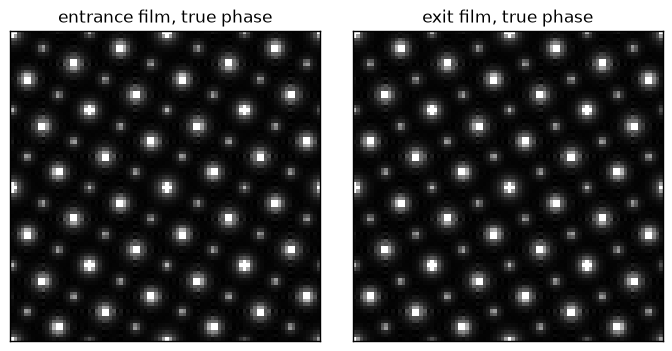

In [6]:
noisy_dataset = add_poisson_noise(dataset, 1e5)

em.visualization.show_2d(
    [truth[0], truth[1]],
    title=["entrance film, true phase", "exit film, true phase"],
    axsize=(3.5, 3.5),
);

## One plane

With one slice, the complex reconstruction of `ptycho_direct_07_complex` is referenced to the
plane where the probe has the given `C10`, here the bilayer's mid-plane. For two films, that
image is close to the sum of their phases:

In [7]:
direct_ptycho = em.diffractive_imaging.DirectPtychography.from_dataset4d(noisy_dataset, **kwargs)

direct_ptycho.reconstruct(deconvolution_kernel="obf", obj_type="complex")
print(f"correlation with the sum of the films: {correlation(direct_ptycho.corrected_bf, truth.sum(0)):.3f}")
print(f"residual: {direct_ptycho.residual_loss():.4f}")

correlation with the sum of the films: 0.858
residual: 0.3811


## Slices

The two films are 7.81 A apart, a quarter of $\lambda / \alpha^2$ = 31.5 A. `num_slices` and
`slice_thicknesses` place slices about the `C10` plane, and `slice_mode` sets how they are found:

- `"sectioned"`, the default, is depth sectioning: one ordinary single-plane reconstruction per
  slice, with the probe defocused to that slice's depth. Any kernel but iCoM can section.
- `"joint"` solves for all the slices together at every spatial frequency, `"obf"` and `"wiener"`
  only.

## Depth sectioning

Nine sections 10 A apart, from 40 A above the mid-plane to 40 A below it:

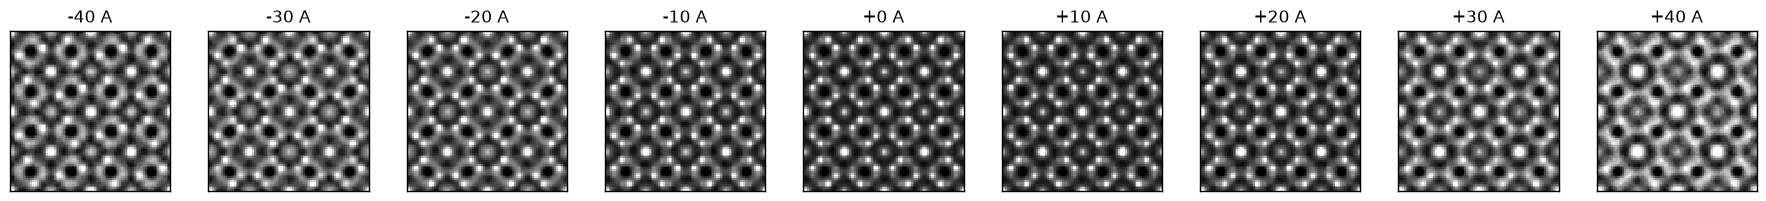

In [8]:
direct_ptycho.reconstruct(
    deconvolution_kernel="obf",
    obj_type="complex",
    num_slices=9,
    slice_thicknesses=10,
)
sections = direct_ptycho.corrected_bf.cpu().numpy()
depths = direct_ptycho.slice_depths

em.visualization.show_2d(
    list(sections),
    title=[f"{z:+.0f} A" for z in depths],
    axsize=(2, 2),
);

Each section is a complete single-plane model of the data, and `section_residuals` holds how much
of the data each leaves unexplained. Against the truth, each film can also be followed through
the stack:

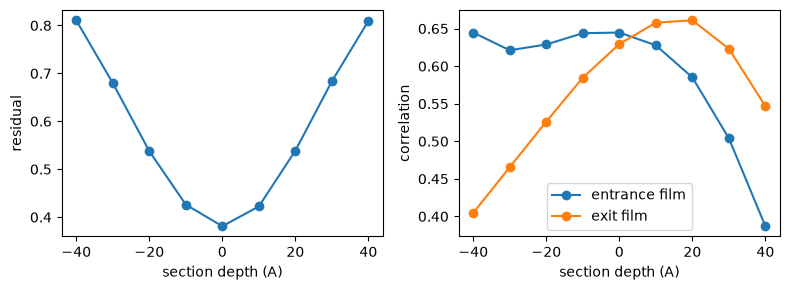

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3))
axs[0].plot(depths, direct_ptycho.section_residuals, "o-")
axs[0].set_xlabel("section depth (A)")
axs[0].set_ylabel("residual")
for film, label in zip(truth, ("entrance film", "exit film")):
    axs[1].plot(depths, [correlation(section, film) for section in sections], "o-", label=label)
axs[1].set_xlabel("section depth (A)")
axs[1].set_ylabel("correlation")
axs[1].legend()
fig.tight_layout()

The residual is smallest at the mid-plane of the bilayer, so sectioning locates the specimen
as a whole. The exit film correlates best with the sections on the exit side, peaking at
+20 A, while the entrance film's correlation stays near 0.64 over the entrance side and falls
past the mid-plane. Both curves are tens of Angstrom wide, as the depth of field predicts, and
at the films' own depths both sections show both films about equally:

In [10]:
direct_ptycho.reconstruct(
    deconvolution_kernel="obf",
    obj_type="complex",
    num_slices=2,
    slice_thicknesses=spacing,
)
print("rows: the sections through the entrance and exit film; columns: entrance and exit film")
print(correlation_table(direct_ptycho.corrected_bf))

rows: the sections through the entrance and exit film; columns: entrance and exit film
[[0.646 0.614]
 [0.64  0.643]]


## Joint solve

Solving for both slices at once instead uses the fact that each film is seen through a
differently defocused probe in every bright-field pixel. `slice_thicknesses` is the gap between
neighbouring slices, and the slices are centred on the `C10` plane, so slice 0 sits at
$-3.9$ A, on the entrance side.

slice depths (A): [-3.90499997  3.90499997]
residual: 0.3706
[[ 0.868  0.127]
 [-0.004  0.815]]


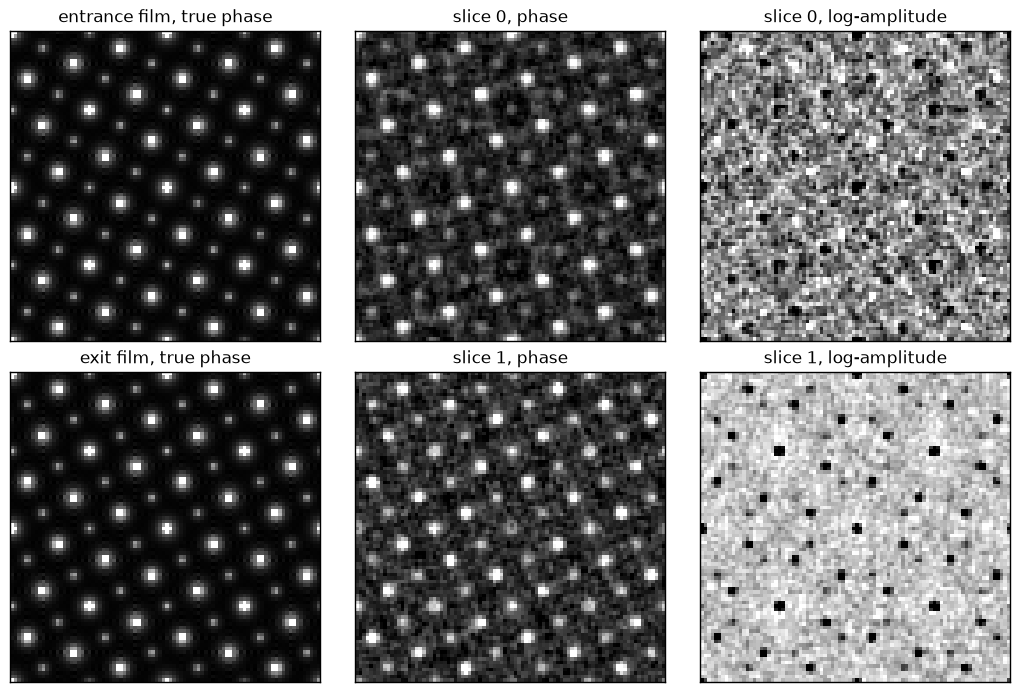

In [11]:
direct_ptycho.reconstruct(
    deconvolution_kernel="obf",
    obj_type="complex",
    num_slices=2,
    slice_thicknesses=spacing,
    slice_mode="joint",
)
print("slice depths (A):", direct_ptycho.slice_depths)
print(f"residual: {direct_ptycho.residual_loss():.4f}")
print(correlation_table(direct_ptycho.corrected_bf.cpu().numpy()))

em.visualization.show_2d(
    [
        [truth[0], direct_ptycho.corrected_bf[0].cpu().numpy(), direct_ptycho.corrected_amplitude[0].cpu().numpy()],
        [truth[1], direct_ptycho.corrected_bf[1].cpu().numpy(), direct_ptycho.corrected_amplitude[1].cpu().numpy()],
    ],
    title=[
        ["entrance film, true phase", "slice 0, phase", "slice 0, log-amplitude"],
        ["exit film, true phase", "slice 1, phase", "slice 1, log-amplitude"],
    ],
    axsize=(3.5, 3.5),
);

Each slice now correlates with its own film and hardly at all with the other. The joint solve
pays for this in noise, since the two slices' columns are nearly parallel at low spatial
frequencies, which matters at low dose (see below). The amplitude channel matters for the
separation too. With pure-phase slices, the amplitude contrast of each film has to be explained
by phase in some slice, and the slices mix.

In [12]:
direct_ptycho.reconstruct(
    deconvolution_kernel="obf",
    num_slices=2,
    slice_thicknesses=spacing,
    slice_mode="joint",
)
print(correlation_table(direct_ptycho.corrected_bf.cpu().numpy()))

[[ 0.646 -0.16 ]
 [ 0.262  0.832]]


## Fitting with the residual

A sectioned stack is one reconstruction per depth rather than one model, so its
`residual_loss()` is `None`, and fits of several slices use the joint solve. Its residual
decreases with every slice the model is allowed, so it can tell whether the specimen has
structure in depth, but the gain from two to three or four slices is small here because the
specimen has only two films:

In [13]:
for num_slices in (1, 2, 3, 4):
    direct_ptycho.reconstruct(
        deconvolution_kernel="obf",
        obj_type="complex",
        num_slices=num_slices,
        slice_thicknesses=2 * spacing / num_slices if num_slices > 1 else None,
        slice_mode="joint",
    )
    print(f"{num_slices} slices: residual {direct_ptycho.residual_loss():.5f}")

1 slices: residual 0.38110
2 slices: residual 0.37057
3 slices: residual 0.36797
4 slices: residual 0.36758


The slices are placed relative to the `C10` plane, so `C10` has to be the plane between the
films. One slice is enough to find it, since its residual is smallest when the plane sits in the
middle of the specimen. `fit_hyperparameters_gradient`, from `ptycho_direct_06_hyperparameters`,
finds it here starting 30 A away:

In [14]:
direct_ptycho.hyperparameter_state.optimized_aberrations = {"C10": C10 + 30}

direct_ptycho.fit_hyperparameters_gradient(
    ("C10",),
    deconvolution_kernel="obf",
    obj_type="complex",
    verbose=True,
);
print(f"{len(direct_ptycho._gradient_fit_history)} evaluations")

Optimized state:

 HyperparameterState(
  initial_aberrations={'C10': -100.0},
  initial_rotation_angle_deg=0,
  optimized_aberrations={'C10': -99.67311096191406},
  optimized_rotation_angle_deg=0.0,
)
8 evaluations


The spacing itself is a different matter. When the slices are much closer than
$\lambda / \alpha^2$, the residual barely depends on it:

In [15]:
for gap in (4, 6, spacing, 10, 14):
    direct_ptycho.reconstruct(
        deconvolution_kernel="obf",
        obj_type="complex",
        num_slices=2,
        slice_thicknesses=gap,
        slice_mode="joint",
    )
    print(
        f"gap {gap:5.2f} A: residual {direct_ptycho.residual_loss():.5f}, "
        f"correlations {correlation_table(direct_ptycho.corrected_bf.cpu().numpy()).tolist()}"
    )

gap  4.00 A: residual 0.37084, correlations [[0.826, -0.06], [-0.338, 0.67]]
gap  6.00 A: residual 0.37070, correlations [[0.858, 0.065], [-0.173, 0.757]]
gap  7.81 A: residual 0.37056, correlations [[0.87, 0.156], [-0.043, 0.805]]
gap 10.00 A: residual 0.37036, correlations [[0.872, 0.243], [0.086, 0.834]]
gap 14.00 A: residual 0.37004, correlations [[0.859, 0.354], [0.251, 0.845]]


Over a factor of three in the gap the residual changes only in its fourth decimal, and it keeps
decreasing past the true spacing, so fitting `"slice_thicknesses"` with
`fit_hyperparameters_gradient` ends near 17 A on these data. The slices still separate at the
wrong gaps, but less cleanly the further the gap is from the truth. When the spacing is well
below $\lambda / \alpha^2$, take it from what is known about the specimen rather than from the
residual.

## Low dose

At 1e4 e/A$^2$ the two slices' columns are nearly parallel at low spatial frequencies, and the
joint solve amplifies the noise there. `ridge` regularizes the solve. As it grows, each slice
tends to its own plane's reconstruction, trading separation for noise. The `"wiener"` kernel
instead solves the same equations for the most probable object, given a signal spectrum it
estimates from the data, which shrinks the frequencies the data cannot support.

obf [[0.686, 0.11], [-0.004, 0.595]]
obf, ridge 1e-2 [[0.732, 0.216], [0.135, 0.666]]
wiener [[0.819, 0.199], [0.048, 0.791]]


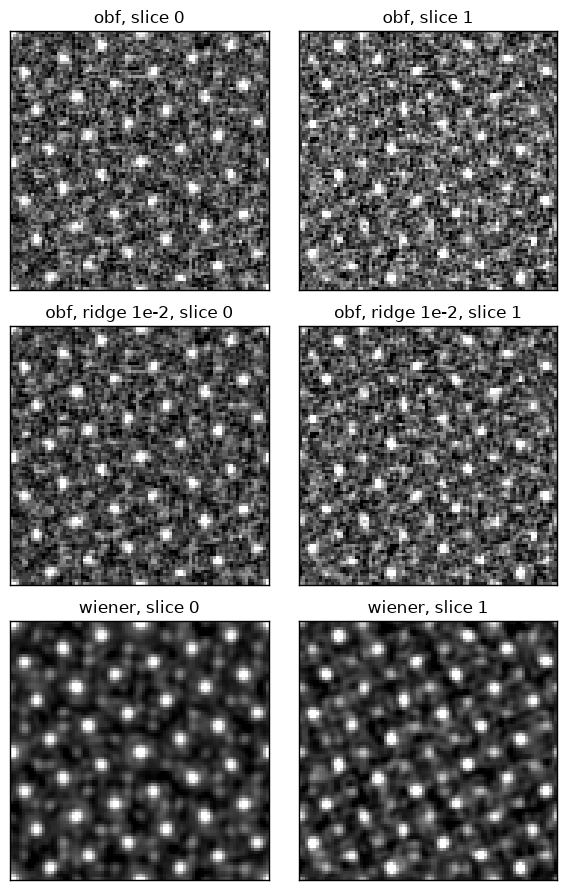

In [16]:
low_dose = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    add_poisson_noise(dataset, 1e4), **kwargs
)

images = {}
for label, settings in (
    ("obf", dict(deconvolution_kernel="obf")),
    ("obf, ridge 1e-2", dict(deconvolution_kernel="obf", ridge=1e-2)),
    ("wiener", dict(deconvolution_kernel="wiener")),
):
    low_dose.reconstruct(
        obj_type="complex", num_slices=2, slice_thicknesses=spacing, slice_mode="joint", **settings
    )
    images[label] = low_dose.corrected_bf.cpu().numpy()
    print(label, correlation_table(images[label]).tolist())

em.visualization.show_2d(
    [list(images[label]) for label in images],
    title=[[f"{label}, slice {n}" for n in (0, 1)] for label in images],
    axsize=(3, 3),
);

The ridge raises each slice's correlation with its own film, at the cost of more of the other
film in it. The Wiener estimate raises the correlations with the own films further, with less
of the other film than the ridge leaves, and its images are visibly less noisy, since it
suppresses the frequencies where the estimated signal is below the noise.

## Tilt series

Tilting the specimen by a small angle $\theta$ displaces a layer at depth $z$ sideways by
$z\theta$, which multiplies that slice's columns at scan frequency $\mathbf{q}$ by
$\exp(-2\pi i z \theta \cdot \mathbf{q})$. Slices whose columns are nearly parallel in one
acquisition are told apart by how they move between tilts, so solving several acquisitions
jointly separates them better than one acquisition with the same total dose.

The simulated series has the untilted scan and four tilts of 18 mrad, about one degree. Each
acquisition also has a small scan offset, standing in for drift.

In [17]:
series_dataset = em.core.io.load("../../data/STO-twisted-bilayer_300kV_25mrad_tilt-series.zip")
tilt_angles = np.asarray(series_dataset.metadata["tilt_angles"])
print(series_dataset.shape)
print("tilts (mrad):", tilt_angles.tolist())

(5, 88, 88, 55, 55)
tilts (mrad): [[0.0, 0.0], [-18.0, 0.0], [18.0, 0.0], [0.0, -18.0], [0.0, 18.0]]


We split a total dose of 1e5 e/A$^2$ equally over the five acquisitions, and compare with one
untilted acquisition that gets all of it. `DirectPtychography.from_tilt_series` builds one
reconstruction per dataset, with shared keyword arguments and optional `per_dataset_kwargs`
for anything that differs between them, such as each acquisition's own aberrations.

In [18]:
total_dose = 1e5
datasets = [
    add_poisson_noise(series_dataset[n], total_dose / len(tilt_angles), seed=n)
    for n in range(len(tilt_angles))
]
series = em.diffractive_imaging.DirectPtychography.from_tilt_series(datasets, tilt_angles, **kwargs)

one_acquisition = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    add_poisson_noise(series_dataset[0], total_dose, seed=99), **kwargs
)
print(len(series), "acquisitions")

5 acquisitions


### Registration

Each acquisition's content is displaced by its drift, and here also because the simulation
tilts the beam about the specimen's entrance surface, which moves the mid-plane by
$z_\text{mid}\,\theta$. `register` measures both from the single-plane reconstructions, whose
projection a small tilt barely changes. The bilayer's pattern repeats every few Angstrom, so the
search is restricted to `max_shift`, below half that period.

In [19]:
series.register(max_shift=1.5)

offsets = np.asarray(series_dataset.metadata["scan_offsets"])
height = series_dataset.metadata["tilt_axis_height"]
expected = -offsets + height * tilt_angles * 1e-3
for n in range(len(series)):
    print(f"acquisition {n}: registered {np.round(series.shifts[n], 3).tolist()} A, "
          f"expected {np.round(expected[n], 3).tolist()} A")

acquisition 0: registered [0.0, 0.0] A, expected [0.0, 0.0] A
acquisition 1: registered [-0.422, 0.198] A, expected [-0.441, 0.2] A
acquisition 2: registered [0.372, -0.347] A, expected [0.391, -0.35] A
acquisition 3: registered [-0.198, -0.372] A, expected [-0.2, -0.391] A
acquisition 4: registered [0.347, 0.285] A, expected [0.35, 0.291] A


### The joint solve over the tilts

A tilt series is always solved jointly, since the tilts tell slices apart only when they are
fitted together:

   obf, one acquisition: [[0.869, 0.122], [-0.014, 0.815]]
   obf, five tilts:      [[0.919, 0.087], [0.033, 0.878]]
wiener, one acquisition: [[0.865, 0.144], [-0.014, 0.846]]
wiener, five tilts:      [[0.896, 0.092], [-0.001, 0.893]]


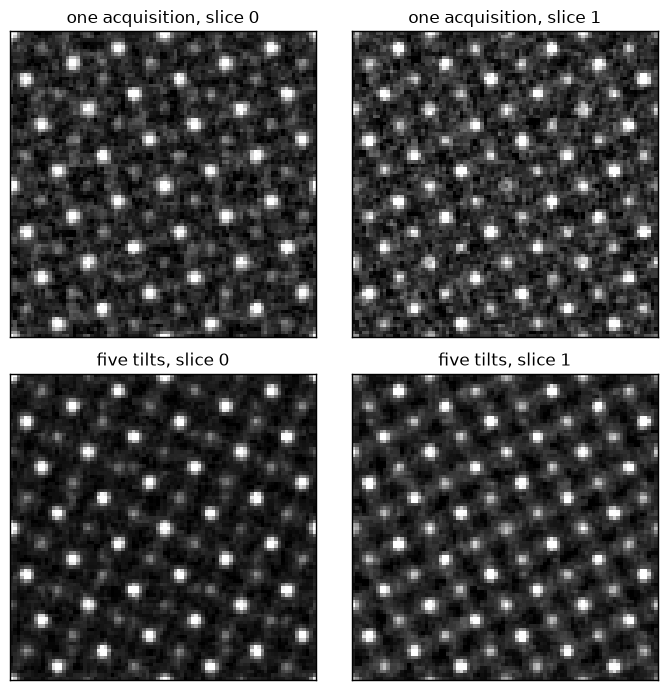

In [20]:
reconstruct_kwargs = dict(
    obj_type="complex", num_slices=2, slice_thicknesses=spacing, slice_mode="joint"
)

for kernel in ("obf", "wiener"):
    series.reconstruct(deconvolution_kernel=kernel, **reconstruct_kwargs)
    one_acquisition.reconstruct(deconvolution_kernel=kernel, **reconstruct_kwargs)
    print(f"{kernel:>6}, one acquisition: {correlation_table(one_acquisition.corrected_bf).tolist()}")
    print(f"{kernel:>6}, five tilts:      {correlation_table(series.corrected_bf).tolist()}")

series.reconstruct(deconvolution_kernel="obf", **reconstruct_kwargs)
one_acquisition.reconstruct(deconvolution_kernel="obf", **reconstruct_kwargs)
em.visualization.show_2d(
    [list(one_acquisition.corrected_bf.cpu().numpy()), list(series.corrected_bf.cpu().numpy())],
    title=[["one acquisition, slice 0", "one acquisition, slice 1"],
           ["five tilts, slice 0", "five tilts, slice 1"]],
    axsize=(3.5, 3.5),
);

At the same total dose, the five tilts raise both slices' correlations with their own films,
from 0.87 and 0.82 to 0.92 and 0.88 for OBF, and the cross-talk stays small.

The residual also tells the right tilts from wrong ones. With every tilt reversed, each slice
is moved the wrong way between acquisitions:

In [21]:
reversed_series = em.diffractive_imaging.DirectPtychographyTiltSeries(
    series.reconstructions, -series.tilt_angles, shifts=series.shifts
)
reversed_series.reconstruct(deconvolution_kernel="obf", **reconstruct_kwargs)
series.reconstruct(deconvolution_kernel="obf", **reconstruct_kwargs)
print(f"residual with the true tilts {series.residual_loss():.5f}, reversed {reversed_series.residual_loss():.5f}")
print("reversed:", correlation_table(reversed_series.corrected_bf).tolist())

residual with the true tilts 0.74825, reversed 0.75498
reversed: [[0.447, 0.788], [0.818, 0.356]]


The residual rises, and the two slices swap films, since reversing every tilt has the same
effect as reversing the order of the slices in depth.

### Saving and loading

`save` writes every acquisition, the tilts, the registered shifts and the last joint
reconstruction to one file, and `em.core.io.load` restores a series that can be reconstructed
again.

In [22]:
import os

os.makedirs("outputs", exist_ok=True)
series.save("outputs/tilt_series.zip", mode="o")
restored = em.core.io.load("outputs/tilt_series.zip")

print(type(restored).__name__, len(restored), "acquisitions")
print("same shifts:", np.array_equal(restored.shifts, series.shifts))
print("same reconstruction:", np.array_equal(restored.obj, series.obj))

DirectPtychographyTiltSeries 5 acquisitions
same shifts: True
same reconstruction: True


## Summary

| option | call |
|---|---|
| depth sectioning | `reconstruct(num_slices=9, slice_thicknesses=10)`, one plane per depth, any kernel but iCoM |
| joint solve | `reconstruct(num_slices=2, slice_thicknesses=7.81, slice_mode="joint")`, `"obf"` and `"wiener"` |
| reference plane | `fit_hyperparameters_gradient(("C10",))` with one slice |
| low dose | `ridge`, or `deconvolution_kernel="wiener"` |
| tilt series | `DirectPtychography.from_tilt_series(datasets, tilt_angles_mrad, **kwargs)`, solved jointly |
| drift | `series.register(max_shift=...)`, or set `series.shifts` |
| persistence | `series.save(path)` and `em.core.io.load(path)` |

`fit_hyperparameters_gradient`, `optimize_hyperparameters` and `grid_search_hyperparameters`
all accept `obj_type`, `num_slices`, `slice_thicknesses` and `slice_mode`. A fit with several
slices needs `slice_mode="joint"`, since a sectioned stack has no residual.